In [3]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_ollama import ChatOllama
from dotenv import load_dotenv

In [4]:
load_dotenv()

True

In [5]:
class SubState(TypedDict): 
    input_text: str
    translated_text: str

In [6]:
subgraph_llm = ChatOllama(model="llama3.2")

In [8]:
def translate_text(state: SubState): 
    prompt = f"""
    Translate the following text to hindi.
    Keep it natural and clear. Do not add extra content.

    Text: {state['input_text']}
    """.strip()
    translate_text = subgraph_llm.invoke(prompt).content

    return {'translated_text': translate_text}

In [10]:
subgraph_builder = StateGraph(SubState)
subgraph_builder.add_node("translate_node", translate_text)

subgraph_builder.add_edge(START, "translate_node")
subgraph_builder.add_edge("translate_node", END)

subgraph = subgraph_builder.compile()

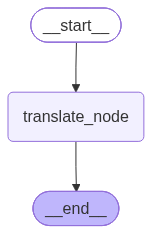

In [11]:
subgraph

In [12]:
class ParentState(TypedDict): 
    question: str 
    answer_eng: str 
    answer_nep: str

In [13]:
parent_llm = ChatOllama(model="llama3.2")

In [14]:
def generate_answer(state: ParentState): 
    answer = parent_llm.invoke(f"Your are a helpful assistant. Answer clearly. \n\nWuestion: {state['question']}").content
    return {'answer_eng': answer}

In [15]:
def translate_answer(state: ParentState): 
    #call the subgraph 
    result = subgraph.invoke({'input_text': state['answer_eng']})

    return {'answer_nep': result['translated_text']}

In [17]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)
parent_builder.add_edge(START, "answer")
parent_builder.add_edge("answer", 'translate')
parent_builder.add_edge("translate", END)

graph = parent_builder.compile()

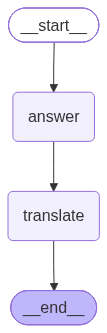

In [18]:
graph

In [ ]:
graph.invoke({'question': "What is quantum physics?"})